In [186]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [187]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head(15)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [188]:
df.drop("id", inplace = True, axis = 1 )

In [189]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [190]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [191]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


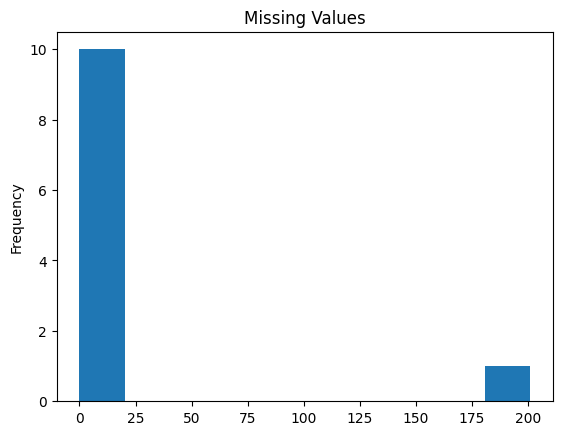

In [192]:
df.isna().sum().plot(kind="hist")
plt.title("Missing Values")
plt.show()

Skew: 1.0553402052962912



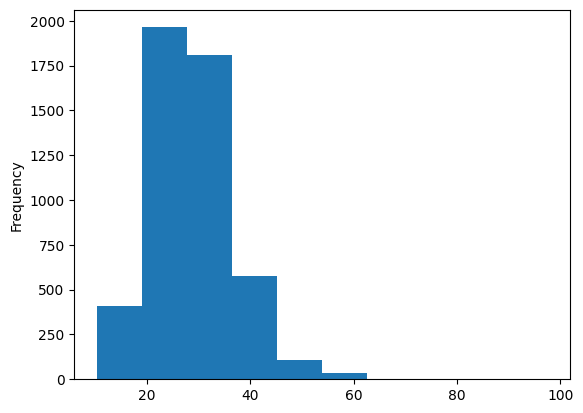

In [193]:
print("Skew:", df["bmi"].skew())
print()
df["bmi"].plot.hist()

plt.show()

In [194]:
from sklearn.impute import SimpleImputer

median_impute = SimpleImputer(missing_values=np.nan, strategy="median")
df["bmi"] = median_impute.fit_transform(df[["bmi"]])

In [195]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [196]:
df.duplicated().sum()

np.int64(0)

In [197]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [198]:
object_columns = [col for col in df.select_dtypes("object").columns ]
object_columns

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [199]:
for col in object_columns :
    print(f"Number of unique value for {col}: {df[col].nunique()}")
    print()
    print(f"unique value for {col}: {df[col].unique()}")
    print("*" * 50)

Number of unique value for gender: 3

unique value for gender: ['Male' 'Female' 'Other']
**************************************************
Number of unique value for ever_married: 2

unique value for ever_married: ['Yes' 'No']
**************************************************
Number of unique value for work_type: 5

unique value for work_type: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
**************************************************
Number of unique value for Residence_type: 2

unique value for Residence_type: ['Urban' 'Rural']
**************************************************
Number of unique value for smoking_status: 4

unique value for smoking_status: ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
**************************************************


In [200]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

ohe = OneHotEncoder(sparse_output=False)
for col in ["gender", "ever_married"]:
  ever_married = ohe.fit_transform(df[[col]])

  frame_ever_married = pd.DataFrame(ever_married, columns=ohe.get_feature_names_out([col]))
  frame_ever_married.head()

  df = pd.concat([df.drop(columns=[col]), frame_ever_married], axis=1)

In [201]:
df.head()

,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes
0,67.0,0,1,Private,Urban,228.69,36.6,formerly smoked,1,0.0,1.0,0.0,0.0,1.0
1,61.0,0,0,Self-employed,Rural,202.21,28.1,never smoked,1,1.0,0.0,0.0,0.0,1.0
2,80.0,0,1,Private,Rural,105.92,32.5,never smoked,1,0.0,1.0,0.0,0.0,1.0
3,49.0,0,0,Private,Urban,171.23,34.4,smokes,1,1.0,0.0,0.0,0.0,1.0
4,79.0,1,0,Self-employed,Rural,174.12,24.0,never smoked,1,1.0,0.0,0.0,0.0,1.0


In [202]:
le = LabelEncoder()
for col in ['work_type', 'Residence_type', 'smoking_status']:
  df[col] = le.fit_transform(df[col])

In [203]:
df.head()

,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes
0,67.0,0,1,2,1,228.69,36.6,1,1,0.0,1.0,0.0,0.0,1.0
1,61.0,0,0,3,0,202.21,28.1,2,1,1.0,0.0,0.0,0.0,1.0
2,80.0,0,1,2,0,105.92,32.5,2,1,0.0,1.0,0.0,0.0,1.0
3,49.0,0,0,2,1,171.23,34.4,3,1,1.0,0.0,0.0,0.0,1.0
4,79.0,1,0,3,0,174.12,24.0,2,1,1.0,0.0,0.0,0.0,1.0


In [204]:
df.dtypes

,0
age,float64
hypertension,int64
heart_disease,int64
work_type,int64
Residence_type,int64
avg_glucose_level,float64
bmi,float64
smoking_status,int64
stroke,int64
gender_Female,float64


In [205]:
df.describe()

,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000
mean,43.226614,0.097456,0.054012,2.167710,0.508023,106.147677,28.862035,1.376908,0.048728,0.585910,0.413894,0.000196,0.343836,0.656164
std,22.612647,0.296607,0.226063,1.090293,0.499985,45.283560,7.699562,1.071534,0.215320,0.492612,0.492578,0.013989,0.475034,0.475034
min,0.080000,0.000000,0.000000,0.000000,0.000000,55.120000,10.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25.000000,0.000000,0.000000,2.000000,0.000000,77.245000,23.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,45.000000,0.000000,0.000000,2.000000,1.000000,91.885000,28.100000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
75%,61.000000,0.000000,0.000000,3.000000,1.000000,114.090000,32.800000,2.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,82.000000,1.000000,1.000000,4.000000,1.000000,271.740000,97.600000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [206]:
colum = [col for col in df.columns]
print((colum))

['age', 'hypertension', 'heart_disease', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes']


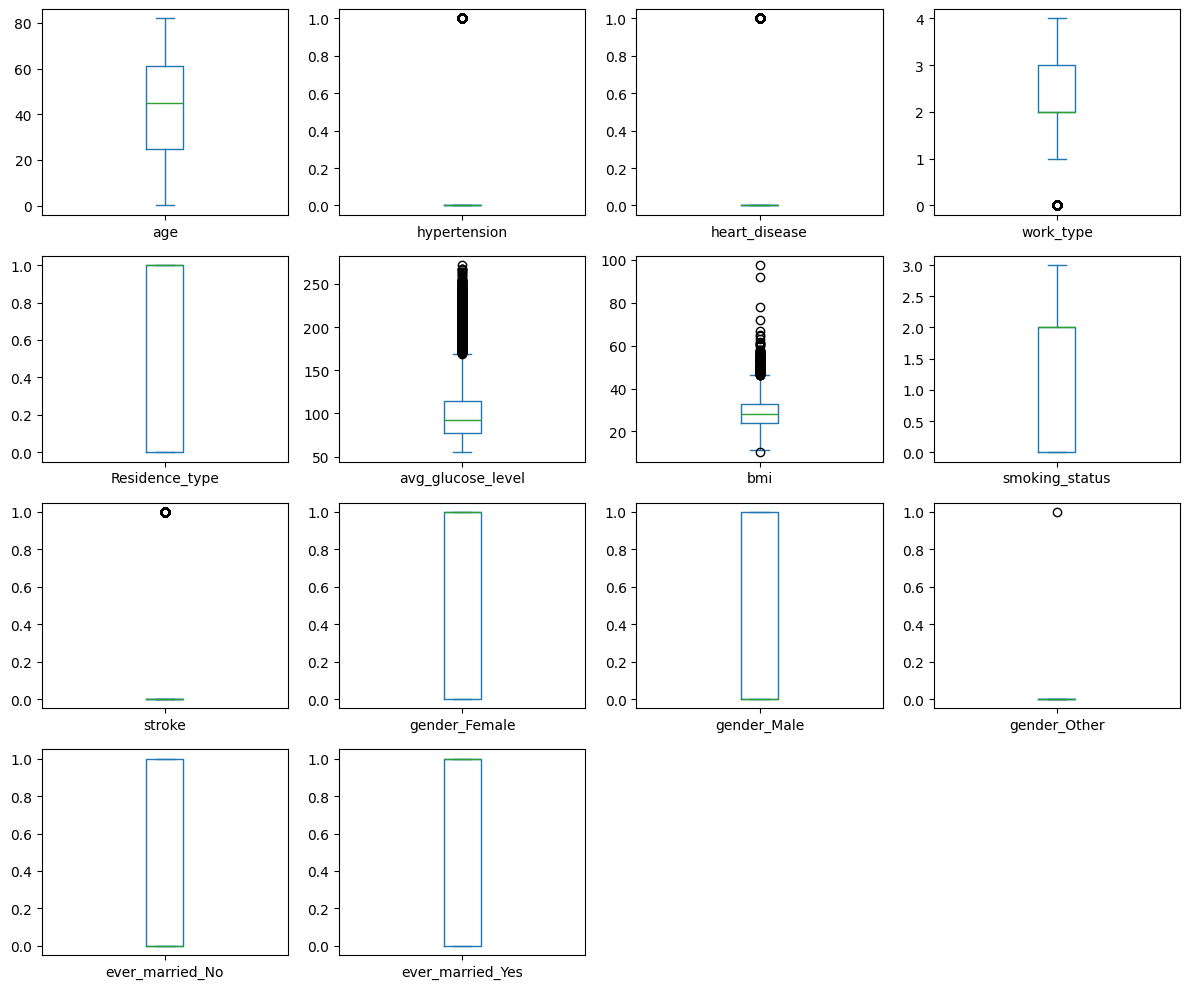

In [207]:
plt.figure(figsize=(12, 10))
for j, col in enumerate(df.columns):
    plt.subplot(4, 4, j + 1)
    df[col].plot.box()


plt.tight_layout()
plt.show()

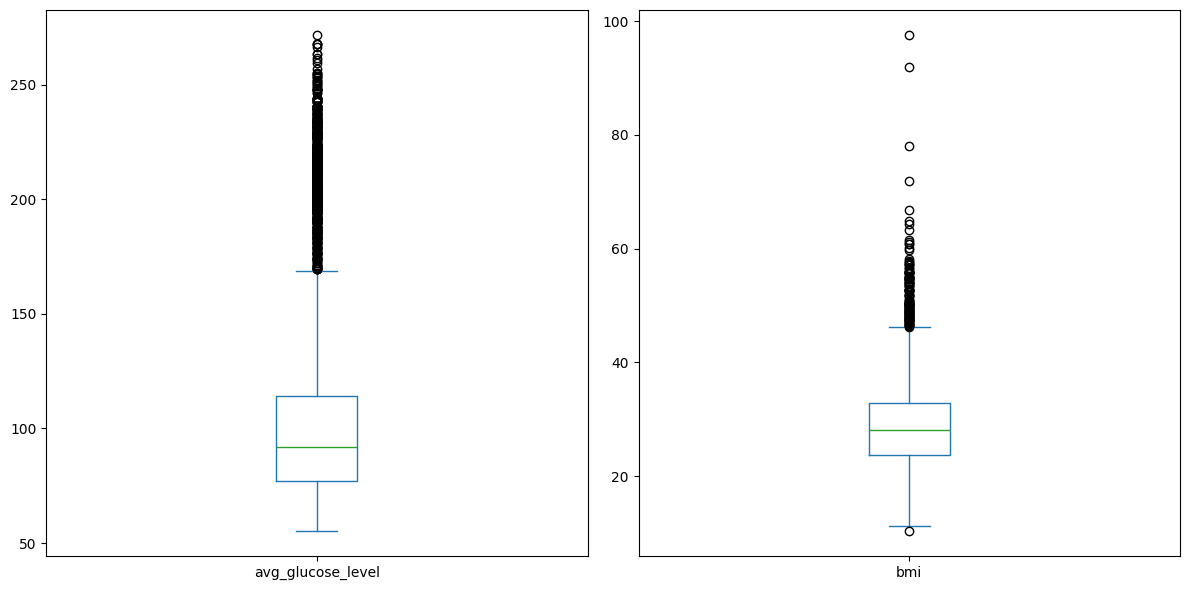

In [208]:
plt.figure(figsize=(12, 6))
for j, col in enumerate([ 'avg_glucose_level', 'bmi']):
    plt.subplot(1, 2, j + 1)
    df[col].plot.box()


plt.tight_layout()
plt.show()

In [209]:
df.shape

(5110, 14)

In [210]:
def remove_outliers(data ,columns) :

  for col in columns :
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

  return data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]

columns = ['avg_glucose_level', 'bmi']
df = remove_outliers(df , columns)
print(df.shape)

(4984, 14)


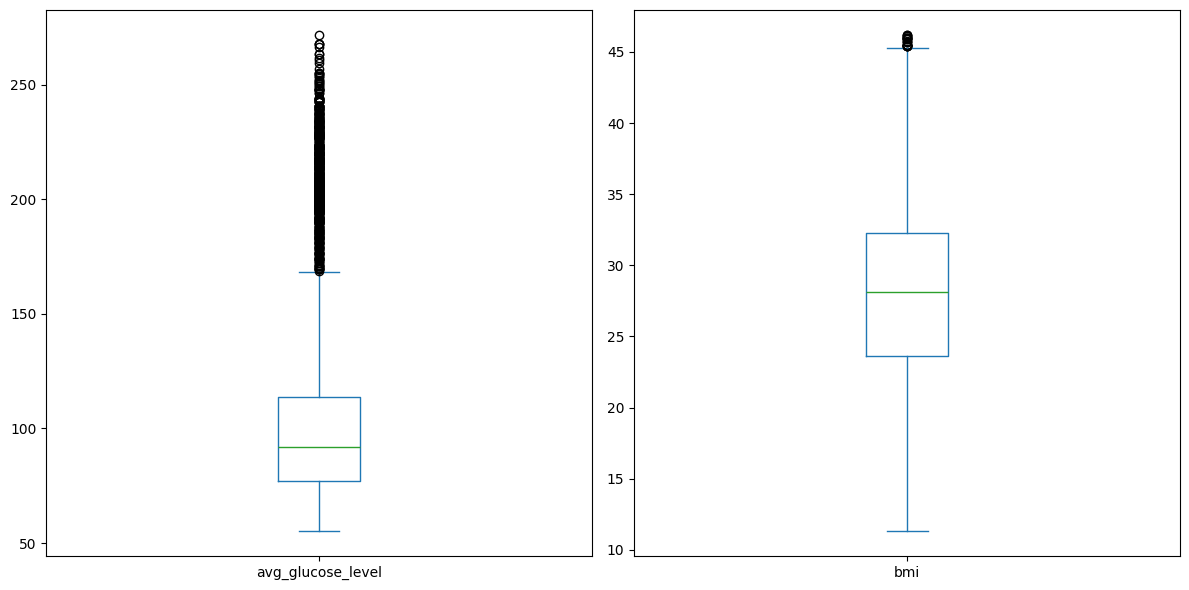

In [211]:
plt.figure(figsize=(12, 6))
for j, col in enumerate([ 'avg_glucose_level', 'bmi']):
    plt.subplot(1, 2, j + 1)
    df[col].plot.box()


plt.tight_layout()
plt.show()

In [212]:
df.shape

(4984, 14)

In [213]:
df['avg_glucose_level'] = np.log1p(df['avg_glucose_level'])

In [214]:
df.shape

(4984, 14)

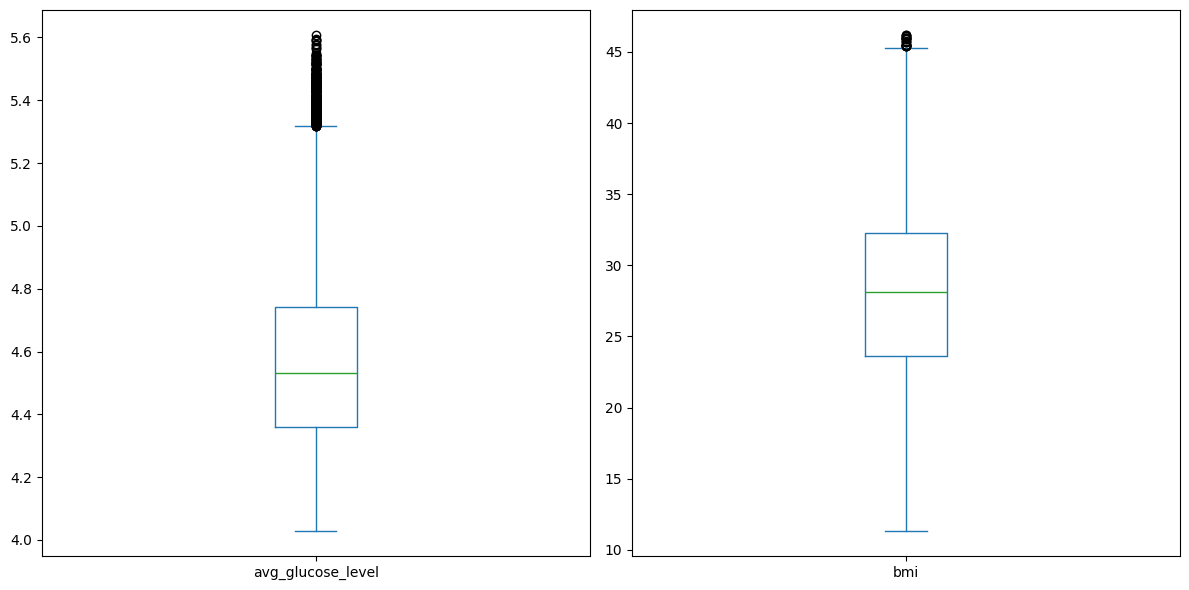

In [215]:
plt.figure(figsize=(12, 6))
for j, col in enumerate([ 'avg_glucose_level', 'bmi']):
    plt.subplot(1, 2, j + 1)
    df[col].plot.box()


plt.tight_layout()
plt.show()

In [216]:
Q1 = df["avg_glucose_level"].quantile(0.25)
Q3 = df["avg_glucose_level"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers =  df[(df["avg_glucose_level"] >= lower_bound) & (df["avg_glucose_level"] <= upper_bound)]
print(len(outliers))

4612


In [217]:
df.head()

,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes
0,67.0,0,1,2,1,5.436731,36.6,1,1,0.0,1.0,0.0,0.0,1.0
1,61.0,0,0,3,0,5.314240,28.1,2,1,1.0,0.0,0.0,0.0,1.0
2,80.0,0,1,2,0,4.672081,32.5,2,1,0.0,1.0,0.0,0.0,1.0
3,49.0,0,0,2,1,5.148831,34.4,3,1,1.0,0.0,0.0,0.0,1.0
4,79.0,1,0,3,0,5.165471,24.0,2,1,1.0,0.0,0.0,0.0,1.0


In [218]:
corr = df.corr(numeric_only= True)
corr

,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes
age,1.000000,0.279343,0.265602,-0.365107,0.014384,0.204152,0.379079,0.270369,0.246717,0.027153,-0.026848,-0.010697,-0.682057,0.682057
hypertension,0.279343,1.000000,0.112555,-0.055181,-0.006688,0.152955,0.154997,0.111674,0.130527,-0.020830,0.020963,-0.004609,-0.166893,0.166893
heart_disease,0.265602,0.112555,1.000000,-0.029844,0.001691,0.151101,0.062316,0.049305,0.135604,-0.085016,0.085120,-0.003423,-0.117048,0.117048
work_type,-0.365107,-0.055181,-0.029844,1.000000,-0.006805,-0.042964,-0.328029,-0.309288,-0.034775,-0.053535,0.053604,-0.002267,0.357858,-0.357858
Residence_type,0.014384,-0.006688,0.001691,-0.006805,1.000000,-0.003728,0.010092,0.010961,0.014322,0.006329,-0.005915,-0.014430,-0.005445,0.005445
avg_glucose_level,0.204152,0.152955,0.151101,-0.042964,-0.003728,1.000000,0.153994,0.056117,0.115730,-0.056273,0.055852,0.014796,-0.133213,0.133213
bmi,0.379079,0.154997,0.062316,-0.328029,0.010092,0.153994,1.000000,0.247947,0.054412,0.000133,0.000226,-0.012507,-0.373000,0.373000
smoking_status,0.270369,0.111674,0.049305,-0.309288,0.010961,0.056117,0.247947,1.000000,0.027663,0.062854,-0.062717,-0.004935,-0.265673,0.265673
stroke,0.246717,0.130527,0.135604,-0.034775,0.014322,0.115730,0.054412,0.027663,1.000000,-0.009182,0.009275,-0.003228,-0.109637,0.109637
gender_Female,0.027153,-0.020830,-0.085016,-0.053535,0.006329,-0.056273,0.000133,0.062854,-0.009182,1.000000,-0.999588,-0.016677,-0.028452,0.028452


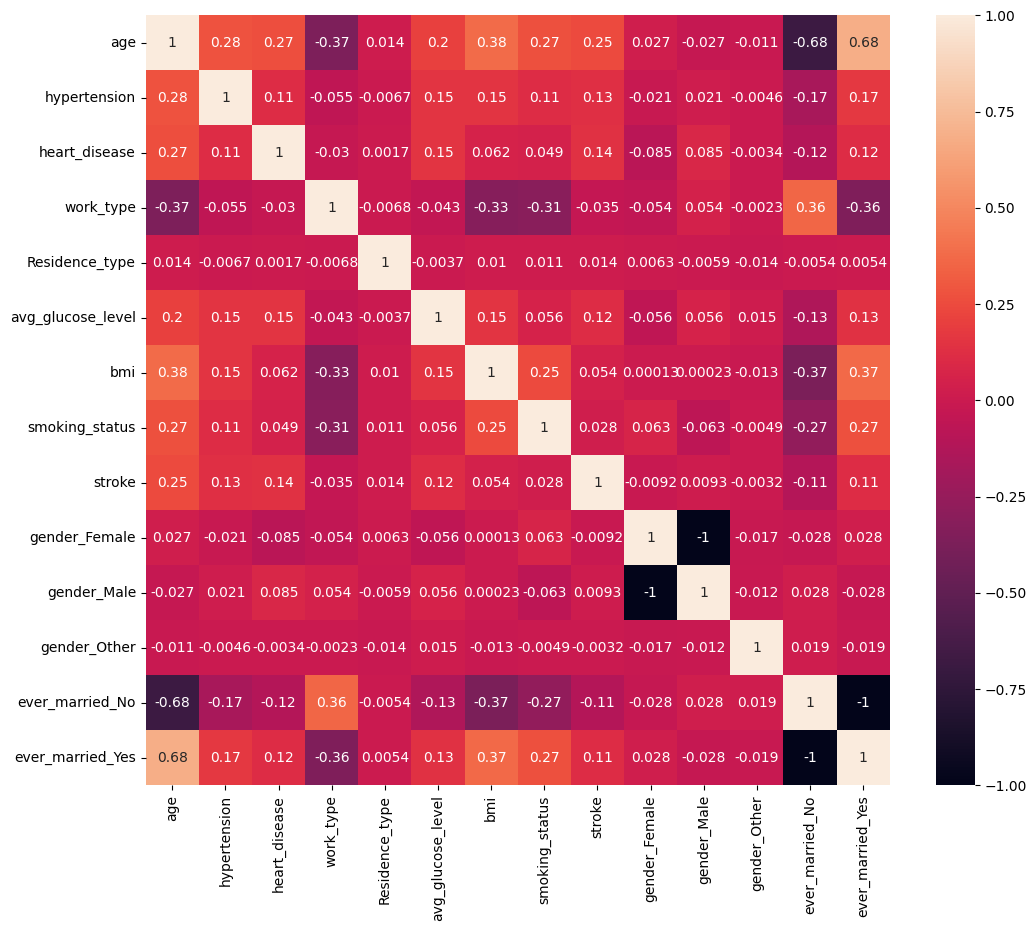

In [219]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot = True )
plt.show()

In [220]:
X = df.drop("stroke" , axis = 1)
y = df["stroke"]

In [221]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [229]:
from sklearn.linear_model import  LogisticRegression

model = LogisticRegression( class_weight='balanced',
    max_iter=1000,
    random_state=42)
model.fit(X_train , y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [230]:
y_pred = model.predict(X_test)

In [231]:
from sklearn.metrics import classification_report , precision_score , recall_score, f1_score, accuracy_score , confusion_matrix

print(precision_score(y_test , y_pred))
print("*" * 50)
print(recall_score(y_test , y_pred))
print("*" * 50)
print(f1_score(y_test , y_pred))
print("*" *50)
print(accuracy_score(y_test , y_pred))
print("*"* 50)
print(classification_report(y_test , y_pred))

0.15690376569037656
**************************************************
0.8823529411764706
**************************************************
0.2664298401420959
**************************************************
0.7239304812834224
**************************************************
              precision    recall  f1-score   support

           0       0.99      0.71      0.83      1411
           1       0.16      0.88      0.27        85

    accuracy                           0.72      1496
   macro avg       0.57      0.80      0.55      1496
weighted avg       0.94      0.72      0.80      1496



In [232]:
cm = confusion_matrix(y_test , y_pred)
cm

array([[1008,  403],
       [  10,   75]])

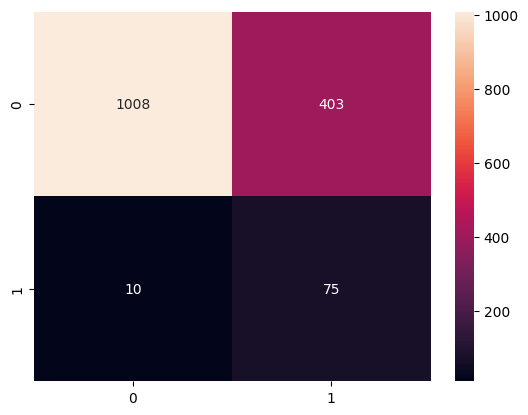

In [233]:
sns.heatmap(cm , annot = True , fmt = "d")
plt.show()